# 11. Heat exchangers

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1, 8 and 10

A heat exchanger passes heat from one flowing fluid to another through a wall. Each side
has a heat transfer coefficient from Chapters 7–10, and the wall and any deposits add
their resistances. This chapter is about what happens along the exchanger. As the fluids
exchange heat, their temperatures change, and the driving temperature difference changes
with them. How the two streams are arranged (in counterflow, in parallel, across each
other, or in several passes) decides how much heat a given area can transfer, and whether
a required outlet temperature can be reached at all.

Two problems from district heating show what is at stake. In a building substation in
Astana, a plate exchanger passes heat from the city network to the building's radiator
circuit; the network wants its water back as cold as possible. How large must the
exchanger be, and what happens when the network cannot deliver its design temperature?
And in the ventilation unit of the same building, a finned coil heats outdoor air from
−35 °C with hot water: if the water flow is throttled, where does the coil freeze first?
The exact solutions for counterflow, shell-and-tube and crossflow exchangers are checked
by collocation and by a grid of small exchangers.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

try:
    from engtransport import exchangers, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import exchangers, reference
from engtransport.plotting import panel_label, use_style

use_style()

## 11.1 Energy balances and the overall coefficient

Each stream is described by its *heat capacity rate* $C = \dot m c_p$ (W/K). With no heat
lost to the surroundings, the heat given up by the hot stream is taken up by the cold one:

$$
\dot Q = C_h\,(T_{h,in} - T_{h,out}) = C_c\,(T_{c,out} - T_{c,in}) .
\tag{11.1}
$$

Locally, the heat crossing an element of area $dA$ is $U(T_h - T_c)\,dA$, where the
overall coefficient adds the resistances in series, as in Chapter 1:

$$
\frac{1}{UA} = \frac{1}{h_h A_h} + R_{f,h} + R_{wall} + R_{f,c} + \frac{1}{h_c A_c} .
\tag{11.2}
$$

The $R_f$ are *fouling* resistances of deposits, which grow in service (Chapter 18).
Throughout this chapter $U$ is taken as constant over the exchanger.

## 11.2 Counterflow and parallel flow

Along a double-pipe or plate exchanger, with $A$ the area from the hot inlet, the two
temperatures obey

$$
C_h\frac{dT_h}{dA} = -U(T_h - T_c) , \qquad
\pm C_c\frac{dT_c}{dA} = -U(T_h - T_c) ,
\tag{11.3}
$$

with the upper sign when the cold stream flows in the same direction (parallel flow) and
the lower one when it flows against it (counterflow). Subtracting the two equations gives
a linear equation for the difference $\Delta T = T_h - T_c$, whose solution is
exponential in $A$. Combining it with Eq. (11.1) gives

$$
\dot Q = UA\,\Delta T_{lm} , \qquad
\Delta T_{lm} = \frac{\Delta T_1 - \Delta T_2}{\ln(\Delta T_1/\Delta T_2)} ,
\tag{11.4}
$$

where $\Delta T_1$ and $\Delta T_2$ are the temperature differences at the two ends of the
exchanger. This is the *log-mean temperature difference*. When all four temperatures are
known, Eq. (11.4) sizes the exchanger directly.

## 11.3 Effectiveness and the number of transfer units

When only the inlets are known, as in rating an existing exchanger, the
*effectiveness–NTU* form is more direct. The most heat the streams could exchange is
$\dot Q_{max} = C_{min}(T_{h,in} - T_{c,in})$, reached in an infinitely long counterflow
exchanger by the stream with the smaller capacity rate $C_{min}$. The *effectiveness*
$\varepsilon = \dot Q/\dot Q_{max}$ then depends only on two numbers,

$$
\mathrm{NTU} = \frac{UA}{C_{min}} , \qquad C_r = \frac{C_{min}}{C_{max}} ,
\tag{11.5}
$$

the *number of transfer units*, a dimensionless size, and the capacity ratio. Solving
Eqs. (11.3) gives, for counterflow and parallel flow,

$$
\varepsilon_{counter} = \frac{1 - e^{-\mathrm{NTU}(1 - C_r)}}{1 - C_r\,e^{-\mathrm{NTU}(1 - C_r)}} ,
\tag{11.6}
$$

$$
\varepsilon_{parallel} = \frac{1 - e^{-\mathrm{NTU}(1 + C_r)}}{1 + C_r} .
\tag{11.7}
$$

Counterflow approaches $\varepsilon = 1$ as the exchanger grows. Parallel flow can never
exceed $1/(1 + C_r)$: the two outlets approach the same temperature, and the cold outlet
can never exceed the hot one. In a shell-and-tube exchanger with one shell pass and two
(or any even number of) tube passes, the shell fluid sees one tube pass in counterflow and
one in parallel flow, and

$$
\varepsilon_{1-2} = 2\left[1 + C_r + \sqrt{1 + C_r^2}\,
\frac{1 + e^{-\mathrm{NTU}\sqrt{1 + C_r^2}}}{1 - e^{-\mathrm{NTU}\sqrt{1 + C_r^2}}}\right]^{-1} .
\tag{11.8}
$$

In a single-pass *crossflow* exchanger, such as a finned coil, one fluid flows across the
other, and if neither mixes sideways the temperatures vary over the whole face. Nusselt
solved this case in 1911; Mason (1955) put the solution as a series,

$$
\varepsilon_{cross} = \frac{1}{C_r\,\mathrm{NTU}}\sum_{n=0}^{\infty}
\left[1 - e^{-\mathrm{NTU}}\sum_{m=0}^{n}\frac{\mathrm{NTU}^m}{m!}\right]
\left[1 - e^{-C_r\mathrm{NTU}}\sum_{m=0}^{n}\frac{(C_r\mathrm{NTU})^m}{m!}\right] .
\tag{11.9}
$$

A widely used explicit approximation,
$\varepsilon \approx 1 - \exp[\mathrm{NTU}^{0.22}(e^{-C_r\mathrm{NTU}^{0.78}} - 1)/C_r]$,
is tested against Eq. (11.9) in Section 11.6. For design by Eq. (11.4) with a mixed
arrangement, the counterflow LMTD is multiplied by a *correction factor*

$$
F = \frac{\mathrm{NTU}_{counter}(\varepsilon, C_r)}{\mathrm{NTU}} \le 1 ,
\tag{11.10}
$$

the fraction of the counterflow driving force that the arrangement achieves (Bowman,
Mueller and Nagle 1940 charted it for many arrangements).

In [2]:
for name in ("counterflow", "shell_and_tube_1_2n", "crossflow_exact", "parallel"):
    vals = [exchangers.effectiveness_from_ntu(N, 0.5, name) for N in (0.5, 1.0, 2.0, 4.0)]
    print(f"{name:20s} Cr = 0.5, NTU = 0.5, 1, 2, 4: eps = " + ", ".join(f"{v:.4f}" for v in vals))
print(f"F of the 1-2 exchanger at Cr = 0.5: NTU = 1: {exchangers.lmtd_correction_factor(1.0, 0.5, 'shell_and_tube_1_2n'):.3f},"
      f" NTU = 2: {exchangers.lmtd_correction_factor(2.0, 0.5, 'shell_and_tube_1_2n'):.3f},"
      f" NTU = 3: {exchangers.lmtd_correction_factor(3.0, 0.5, 'shell_and_tube_1_2n'):.3f}")

counterflow          Cr = 0.5, NTU = 0.5, 1, 2, 4: eps = 0.3623, 0.5647, 0.7746, 0.9274
shell_and_tube_1_2n  Cr = 0.5, NTU = 0.5, 1, 2, 4: eps = 0.3569, 0.5399, 0.6931, 0.7565
crossflow_exact      Cr = 0.5, NTU = 0.5, 1, 2, 4: eps = 0.3578, 0.5475, 0.7324, 0.8697
parallel             Cr = 0.5, NTU = 0.5, 1, 2, 4: eps = 0.3518, 0.5179, 0.6335, 0.6650
F of the 1-2 exchanger at Cr = 0.5: NTU = 1: 0.923, NTU = 2: 0.756, NTU = 3: 0.592


At $\mathrm{NTU} = 1$ the arrangements differ by a few per cent; at $\mathrm{NTU} = 4$
counterflow gives 0.93 and parallel flow 0.67, its limit. The shell-and-tube exchanger
loses its efficiency quickly at large NTU: beyond $F \approx 0.8$ more area buys little,
and designers add shells in series instead.

## 11.4 A district-heating substation

A building in Astana takes 400 kW at the design outdoor temperature of −35 °C. Network
water arrives at 110 °C; the building's radiator circuit needs 70 °C and returns at 50 °C;
and the network operator asks for its water back at no more than 55 °C, because cold
return water lowers the losses of the network (Chapters 1 and 4) and raises the output of
the plant. A brazed plate exchanger runs in counterflow:

In [3]:
Q_design, T_ps, T_ss, T_sr, T_pr = 400e3, 110.0, 70.0, 50.0, 55.0
C_p = Q_design / (T_ps - T_pr)
C_s = Q_design / (T_ss - T_sr)
C_min, C_max = min(C_p, C_s), max(C_p, C_s)
Cr_s = C_min / C_max
eps_s = Q_design / (C_min * (T_ps - T_sr))
NTU_s = exchangers.ntu_from_effectiveness(eps_s, Cr_s, "counterflow")
UA_s = NTU_s * C_min
dT_lm = exchangers.lmtd(T_ps - T_ss, T_pr - T_sr)
U_plate = 4000.0                       # W/(m2 K), an assumed value for a clean plate exchanger in water service
print(f"primary {C_p:.0f} W/K ({C_p / 4190:.2f} kg/s), secondary {C_s:.0f} W/K; Cr = {Cr_s:.3f}, eps = {eps_s:.3f}, NTU = {NTU_s:.3f}")
print(f"UA = {UA_s / 1e3:.2f} kW/K by eps-NTU, {Q_design / dT_lm / 1e3:.2f} kW/K by the LMTD ({dT_lm:.2f} K); area {UA_s / U_plate:.1f} m2 at U = {U_plate:.0f}")
T_parallel = (C_p * T_ps + C_s * T_sr) / (C_p + C_s)
print(f"parallel flow: limit eps = {1 / (1 + Cr_s):.3f}; even an infinite exchanger returns the primary at {T_parallel:.1f} C")


def primary_needed(T_supply, UA=UA_s):
    """Primary capacity rate and return temperature that deliver 400 kW, secondary 50 -> 70 C."""
    deficit = lambda C: exchangers.rate_exchanger(UA, C, C_s, T_supply, T_sr)["Q"] - Q_design
    hi = C_p
    while deficit(hi) < 0:
        hi *= 2
        if hi > 1e7:
            return float("nan"), float("nan")
    C = brentq(deficit, 1e3, hi)
    return C, exchangers.rate_exchanger(UA, C, C_s, T_supply, T_sr)["T_h_out"]


for T_sup in (110.0, 100.0, 90.0, 85.0, 80.0):
    C, T_ret = primary_needed(T_sup)
    print(f"network supply {T_sup:.0f} C: primary flow {C / C_p:.2f} times design, return {T_ret:.1f} C")
T_lowest = brentq(lambda T: primary_needed(T)[0] / C_p - 10.0, 80.0, 90.0)
print(f"a primary flow ten times the design value is needed at a supply of {T_lowest:.1f} C")

primary 7273 W/K (1.74 kg/s), secondary 20000 W/K; Cr = 0.364, eps = 0.917, NTU = 3.268
UA = 23.77 kW/K by eps-NTU, 23.77 kW/K by the LMTD (16.83 K); area 5.9 m2 at U = 4000
parallel flow: limit eps = 0.733; even an infinite exchanger returns the primary at 66.0 C
network supply 110 C: primary flow 1.00 times design, return 55.0 C
network supply 100 C: primary flow 1.32 times design, return 58.2 C
network supply 90 C: primary flow 2.12 times design, return 64.0 C
network supply 85 C: primary flow 3.40 times design, return 68.8 C
network supply 80 C: primary flow 14.60 times design, return 76.2 C
a primary flow ten times the design value is needed at a supply of 80.6 C


The exchanger needs $\mathrm{NTU} = 3.27$, $UA = 23.8$ kW/K, about 6 m² of plates: a
small brazed unit. Its effectiveness of 0.92 is reachable only in counterflow. In
parallel flow the primary water could not leave colder than 66 °C however large the
exchanger, and a 1-2 shell-and-tube exchanger could not do it either (Exercise 3).

The network does not always deliver its design temperature. With the same exchanger and
the same building load, a supply of 90 °C needs twice the design primary flow and returns
the water at 64 °C instead of 55 °C, and at about 81 °C it would need ten times the design
flow. The
substation then pulls more water through the network, which raises the return
temperature and the pumping power everywhere. This is why network operators watch return
temperatures.

## 11.5 An air-heating coil and its freezing corner

The same building's ventilation unit takes in 2 kg/s of outdoor air at −35 °C and heats it
to 18 °C in a finned coil fed with network water at 95 °C, returning at 60 °C at design
conditions. Water flows in the tubes, air across them, and neither mixes sideways, so the
coil is a crossflow exchanger, Eq. (11.9). The water in the tubes nearest the air inlet
meets the coldest air, and it is coldest at the end of those tubes. If a control valve
throttles the water, that corner can freeze while the mixed water outlet still looks warm.
`reference.crossflow_cells` computes the temperature field on a grid of small exchangers:

In [4]:
m_air, cp_air, T_ai, T_ao, T_wi, T_wo = 2.0, 1006.0, -35.0, 18.0, 95.0, 60.0
C_air = m_air * cp_air
Q_coil = C_air * (T_ao - T_ai)
C_w = Q_coil / (T_wi - T_wo)
eps_c = Q_coil / (min(C_air, C_w) * (T_wi - T_ai))
NTU_c = exchangers.ntu_from_effectiveness(eps_c, min(C_air, C_w) / max(C_air, C_w), "crossflow_exact")
UA_c = NTU_c * min(C_air, C_w)
print(f"coil: {Q_coil / 1e3:.1f} kW; water {C_w:.0f} W/K ({C_w / 4190:.2f} kg/s), air {C_air:.0f} W/K;"
      f" eps = {eps_c:.4f}, NTU = {NTU_c:.4f}, UA = {UA_c:.0f} W/K")


def coil(fraction, n=120):
    """Coil with the water flow reduced to `fraction` of design (UA kept): fields and outlets."""
    Cw = fraction * C_w
    Cmin = min(Cw, C_air)
    r = reference.crossflow_cells(UA_c / Cmin, Cmin / max(Cw, C_air), n, "x" if Cw <= C_air else "y")
    Tw_field = T_ai + (T_wi - T_ai) * r["Tx"]          # water flows along x (tubes), air along y
    Q = r["eps"] * Cmin * (T_wi - T_ai)
    return {"Tw": Tw_field, "T_min": Tw_field[0, -1], "Tw_out": T_wi - Q / Cw, "Ta_out": T_ai + Q / C_air, "Q": Q}


for f in (1.0, 0.5, 0.35, 0.2):
    c = coil(f)
    print(f"water flow {f:4.2f} of design: mixed water outlet {c['Tw_out']:5.1f} C, coldest water {c['T_min']:6.1f} C,"
          f" air out {c['Ta_out']:5.1f} C, {c['Q'] / 1e3:5.1f} kW")
f_freeze = brentq(lambda f: coil(f)["T_min"], 0.05, 1.0)
c_f = coil(f_freeze)
print(f"the coldest water reaches 0 C at {100 * f_freeze:.0f} % of the design flow, when the mixed outlet is still {c_f['Tw_out']:.1f} C")

coil: 106.6 kW; water 3047 W/K (0.73 kg/s), air 2012 W/K; eps = 0.4077, NTU = 0.6397, UA = 1287 W/K
water flow 1.00 of design: mixed water outlet  60.0 C, coldest water   50.3 C, air out  18.0 C, 106.6 kW
water flow 0.50 of design: mixed water outlet  34.2 C, coldest water   21.0 C, air out  11.0 C,  92.6 kW
water flow 0.35 of design: mixed water outlet  17.6 C, coldest water    4.0 C, air out   6.0 C,  82.5 kW
water flow 0.20 of design: mixed water outlet  -8.6 C, coldest water  -19.2 C, air out  -3.6 C,  63.2 kW
the coldest water reaches 0 C at 32 % of the design flow, when the mixed outlet is still 13.5 C


At design the mixed water leaves at 60 °C, but the tube nearest the air inlet already
delivers water at 50 °C. If the valve closes to 32 % of the design flow, the water in that
corner reaches 0 °C while the mixed outlet is still at 13 °C: a thermometer on the return
pipe would see nothing wrong. Frost thermostats on air heaters are therefore placed on the
coil face downstream of the coldest tubes, and valves are not allowed to close fully in
frost.

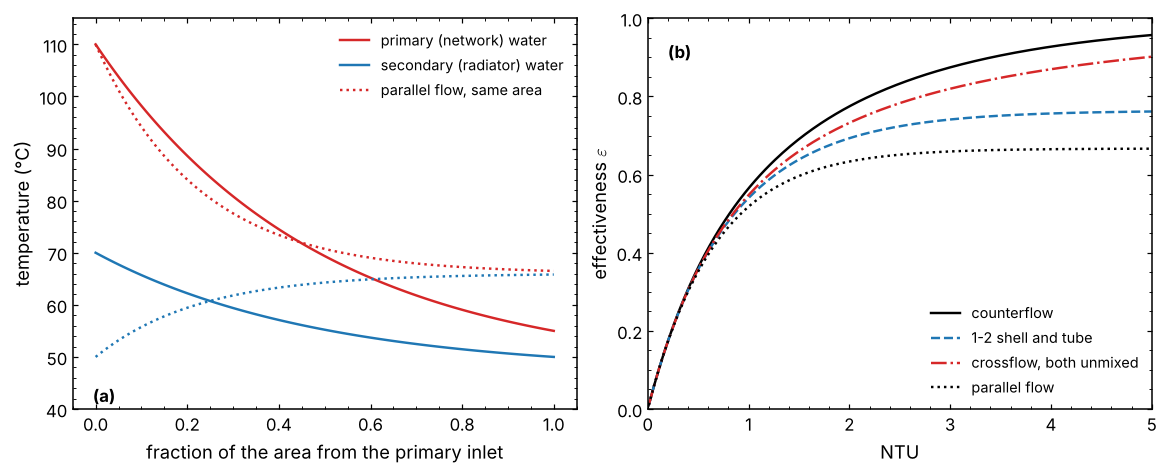

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
A_frac = np.linspace(0, 1, 101)
NTU_h, NTU_c_ = UA_s / C_p, UA_s / C_s
# counterflow profiles, from the closed-form solution of Eqs. (11.3)
a = NTU_h - NTU_c_
dT0 = T_ps - T_ss                                    # difference at the hot inlet end
dT = dT0 * np.exp(-a * A_frac)
Th = T_ps - NTU_h * dT0 * (1 - np.exp(-a * A_frac)) / a
Tc = Th - dT
ax1.plot(A_frac, Th, "C3-", label="primary (network) water")
ax1.plot(A_frac, Tc, "C0-", label="secondary (radiator) water")
# parallel flow with the same UA and inlets
r_par = exchangers.rate_exchanger(UA_s, C_p, C_s, T_ps, T_sr, "parallel")
b = NTU_h + NTU_c_
dT_par = (T_ps - T_sr) * np.exp(-b * A_frac)
Th_par = T_ps - NTU_h * (T_ps - T_sr) * (1 - np.exp(-b * A_frac)) / b
ax1.plot(A_frac, Th_par, "C3:", label="parallel flow, same area")
ax1.plot(A_frac, Th_par - dT_par, "C0:")
ax1.set_xlabel("fraction of the area from the primary inlet")
ax1.set_ylabel("temperature (°C)")
ax1.set_ylim(40, 115)
ax1.legend(loc="upper right")
panel_label(ax1, "(a)", x=0.04, y=0.06)

NTUs = np.linspace(0.01, 5, 200)
for name, style, label in (("counterflow", "k-", "counterflow"), ("shell_and_tube_1_2n", "C0--", "1-2 shell and tube"),
                           ("crossflow_exact", "C3-.", "crossflow, both unmixed"), ("parallel", "k:", "parallel flow")):
    ax2.plot(NTUs, [exchangers.effectiveness_from_ntu(N, 0.5, name) for N in NTUs], style, label=label)
ax2.set_xlabel("NTU")
ax2.set_ylabel(r"effectiveness $\varepsilon$")
ax2.set_xlim(0, 5)
ax2.set_ylim(0, 1)
ax2.legend(loc="lower right")
panel_label(ax2, "(b)", x=0.04, y=0.94)
plt.show()

**Figure 11.1.** (a) Temperatures along the substation exchanger in counterflow at design,
and in parallel flow with the same area and inlets, where the primary water cools only to
66.5 °C and the exchanger delivers 316 kW instead of 400 kW. (b) Effectiveness against NTU for four arrangements at $C_r = 0.5$,
Eqs. (11.6)–(11.9).

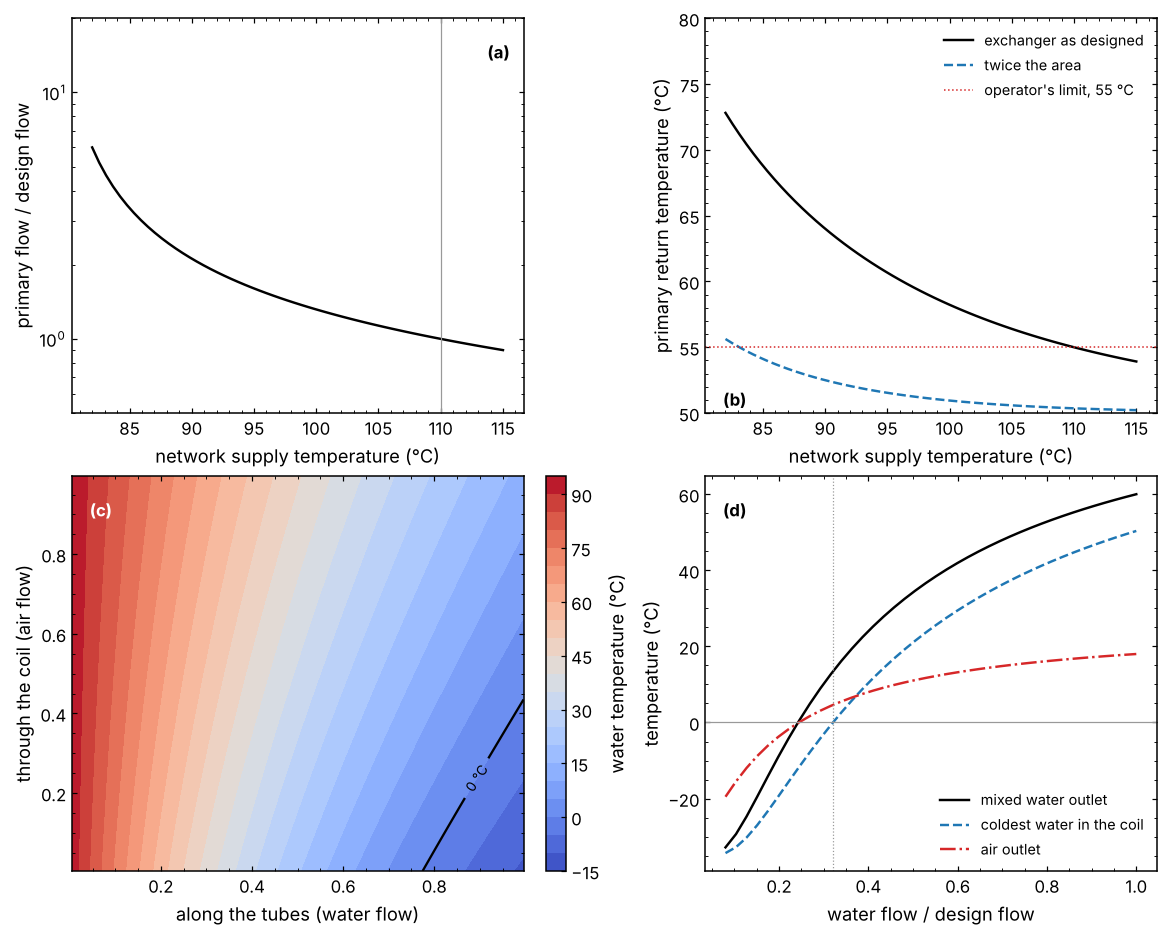

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

T_sups = np.linspace(82.0, 115.0, 60)
needs = np.array([primary_needed(T) for T in T_sups])
ax1.semilogy(T_sups, needs[:, 0] / C_p, "k-")
ax1.axvline(110.0, color="0.6", lw=0.8)
ax1.set_xlabel("network supply temperature (°C)")
ax1.set_ylabel("primary flow / design flow")
ax1.set_ylim(0.5, 20)
panel_label(ax1, "(a)", x=0.92, y=0.94)

ax2.plot(T_sups, needs[:, 1], "k-", label="exchanger as designed")
needs_big = np.array([primary_needed(T, UA=2 * UA_s) for T in T_sups])
ax2.plot(T_sups, needs_big[:, 1], "C0--", label="twice the area")
ax2.axhline(55.0, color="C3", ls=":", lw=1.0, label="operator's limit, 55 °C")
ax2.set_xlabel("network supply temperature (°C)")
ax2.set_ylabel("primary return temperature (°C)")
ax2.set_ylim(50, 80)
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", x=0.04, y=0.06)

c_show = coil(0.25)
n = c_show["Tw"].shape[0]
xs = (np.arange(n) + 0.5) / n
im = ax3.contourf(xs, xs, c_show["Tw"], levels=np.arange(-15, 100, 5), cmap="coolwarm")
cs = ax3.contour(xs, xs, c_show["Tw"], levels=[0.0], colors="k", linewidths=1.5)
ax3.clabel(cs, fmt="0 °C", fontsize=9)
fig.colorbar(im, ax=ax3, label="water temperature (°C)")
ax3.set_xlabel("along the tubes (water flow)")
ax3.set_ylabel("through the coil (air flow)")
panel_label(ax3, "(c)", x=0.04, y=0.94, color="w")

fracs = np.linspace(0.08, 1.0, 40)
coils = [coil(f, n=80) for f in fracs]
ax4.plot(fracs, [c["Tw_out"] for c in coils], "k-", label="mixed water outlet")
ax4.plot(fracs, [c["T_min"] for c in coils], "C0--", label="coldest water in the coil")
ax4.plot(fracs, [c["Ta_out"] for c in coils], "C3-.", label="air outlet")
ax4.axhline(0.0, color="0.6", lw=0.8)
ax4.axvline(f_freeze, color="0.6", ls=":", lw=0.8)
ax4.set_xlabel("water flow / design flow")
ax4.set_ylabel("temperature (°C)")
ax4.legend(loc="lower right")
panel_label(ax4, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 11.2.** (a) Primary flow the substation needs to deliver 400 kW, against the
network supply temperature (design 110 °C). (b) The resulting primary return
temperature, for the exchanger as designed and for one twice as large. (c) Water
temperature over the face of the air-heating coil with the water flow throttled to 25 %:
air enters at the bottom at −35 °C and water at the left at 95 °C; the water inside the
black 0 °C line, at the ends of the first tubes, is freezing. (d) Outlet temperatures and the coldest water
temperature against the water flow.

## 11.6 Checks

**Crossflow.** `reference.crossflow_cells` divides the exchanger into $n \times n$ small
exchangers, each with $1/n^2$ of the area, one row of the first stream and one column of
the second. In each cell the heat flow uses the means of the inlet and outlet temperatures,
and the cells are swept in the direction of both flows. Nothing of the series (11.9) is
used, so the two are independent.

**Shell and tube.** `reference.shell_and_tube_1_2_bvp` solves the three-stream equations
of a 1-2 exchanger (the shell, mixed across its section, and the two tube passes, each
with half the area) by collocation, with the hairpin condition that the second pass
starts at the outlet temperature of the first.

In [7]:
cases = [(1.0, 1.0), (2.0, 0.5), (4.0, 0.25)]
n_cells = [20, 40, 80, 160]
err_cells = {}
for NTU, Cr in cases:
    exact = exchangers.effectiveness_crossflow_exact(NTU, Cr)
    err_cells[(NTU, Cr)] = np.array([abs(reference.crossflow_cells(NTU, Cr, n)["eps"] - exact) for n in n_cells])
    e = err_cells[(NTU, Cr)]
    print(f"crossflow NTU = {NTU}, Cr = {Cr}: exact {exact:.8f}; cells error " + " ".join(f"{v:.1e}" for v in e)
          + f"; order {np.log2(e[-2] / e[-1]):.2f}")
sym = reference.crossflow_cells(2.0, 0.5, 160, "y")["eps"] - reference.crossflow_cells(2.0, 0.5, 160, "x")["eps"]
print(f"swapping which stream has C_min changes the cell result by {sym:.1e}")

NTU_grid = np.linspace(0.1, 6.0, 60)
approx_err = {Cr: np.array([exchangers.effectiveness_from_ntu(N, Cr, "crossflow_both_unmixed")
                            - exchangers.effectiveness_crossflow_exact(N, Cr) for N in NTU_grid]) for Cr in (0.25, 0.5, 1.0)}
worst = max(np.max(np.abs(v)) for v in approx_err.values())
print(f"the explicit approximation differs from Eq. (11.9) by at most {worst:.4f} in eps (NTU <= 6)")

NTU_st = np.linspace(0.2, 5.0, 13)
st_err = {}
for Cr in (0.5, 1.0):
    st_err[Cr] = np.array([abs(reference.shell_and_tube_1_2_bvp(N, Cr)["eps"]
                               - exchangers.effectiveness_from_ntu(N, Cr, "shell_and_tube_1_2n")) for N in NTU_st])
print(f"1-2 shell and tube, collocation against Eq. (11.8): largest difference {max(v.max() for v in st_err.values()):.1e}")
print(f"substation, UA by eps-NTU minus UA by LMTD: {UA_s - Q_design / dT_lm:.1e} W/K")

crossflow NTU = 1.0, Cr = 1.0: exact 0.47622239; cells error 5.1e-05 1.3e-05 3.2e-06 7.9e-07; order 2.00
crossflow NTU = 2.0, Cr = 0.5: exact 0.73240925; cells error 1.3e-04 3.3e-05 8.3e-06 2.1e-06; order 2.00
crossflow NTU = 4.0, Cr = 0.25: exact 0.93401982; cells error 2.9e-04 7.1e-05 1.8e-05 4.5e-06; order 2.00
swapping which stream has C_min changes the cell result by -1.1e-16
the explicit approximation differs from Eq. (11.9) by at most 0.0109 in eps (NTU <= 6)


1-2 shell and tube, collocation against Eq. (11.8): largest difference 6.9e-14
substation, UA by eps-NTU minus UA by LMTD: 1.1e-11 W/K


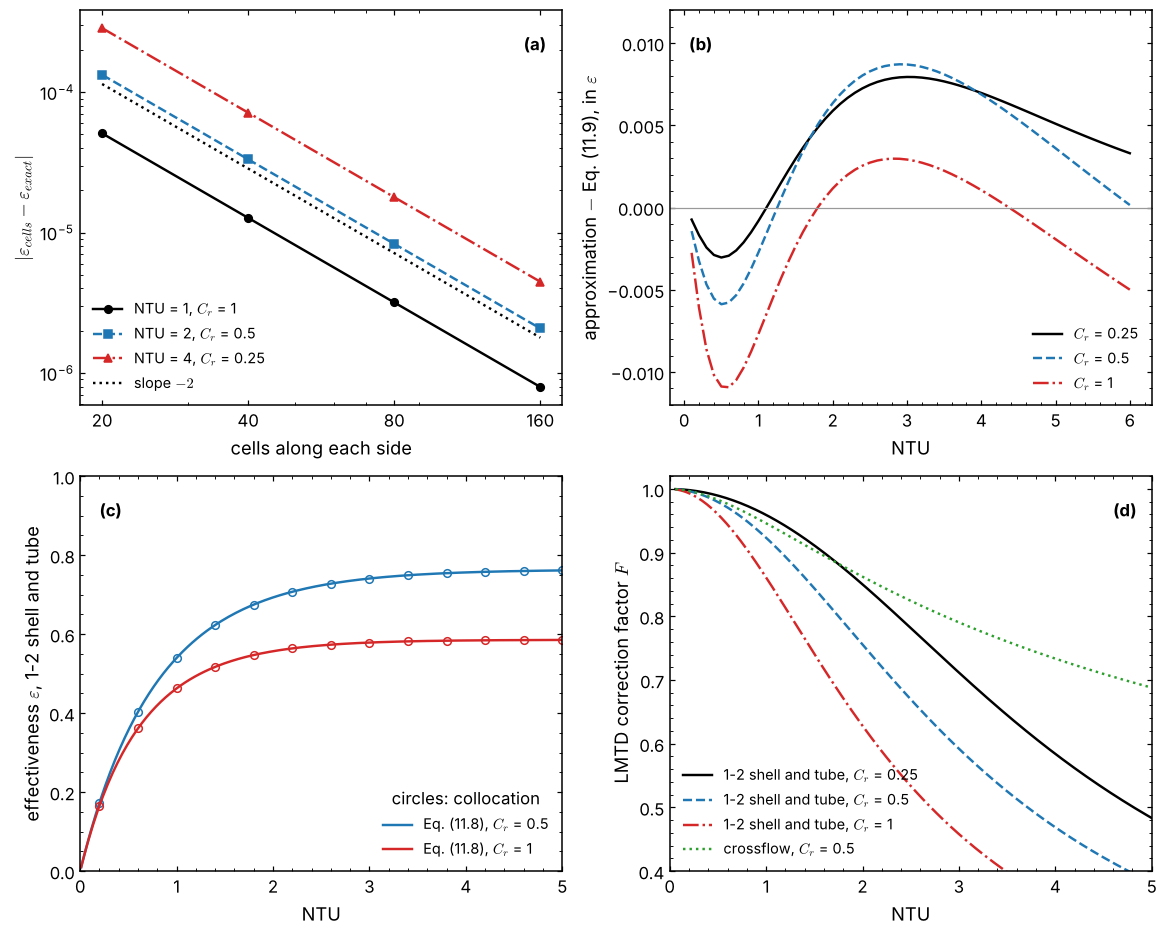

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

for (NTU, Cr), style in zip(cases, ("ko-", "C0s--", "C3^-.")):
    ax1.loglog(n_cells, err_cells[(NTU, Cr)], style, ms=5, label=f"NTU = {NTU:g}, $C_r$ = {Cr:g}")
ax1.loglog(n_cells, 0.4 * err_cells[(4.0, 0.25)][1] * (np.array(n_cells) / 40) ** -2.0, "k:", label="slope $-2$")
ax1.set_xticks(n_cells)
ax1.xaxis.set_major_formatter(plt.ScalarFormatter())
ax1.xaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_xlabel("cells along each side")
ax1.set_ylabel(r"$|\varepsilon_{cells} - \varepsilon_{exact}|$")
ax1.legend(loc="lower left")
panel_label(ax1, "(a)", x=0.92, y=0.94)

for Cr, style in ((0.25, "k-"), (0.5, "C0--"), (1.0, "C3-.")):
    ax2.plot(NTU_grid, approx_err[Cr], style, label=f"$C_r$ = {Cr:g}")
ax2.axhline(0.0, color="0.6", lw=0.8)
ax2.set_xlabel("NTU")
ax2.set_ylabel(r"approximation $-$ Eq. (11.9), in $\varepsilon$")
ax2.set_ylim(-0.012, 0.012)
ax2.legend(loc="lower right")
panel_label(ax2, "(b)", x=0.04, y=0.94)

for Cr, style in ((0.5, "C0"), (1.0, "C3")):
    ax3.plot(NTUs, [exchangers.effectiveness_from_ntu(N, Cr, "shell_and_tube_1_2n") for N in NTUs], style + "-",
             label=f"Eq. (11.8), $C_r$ = {Cr:g}")
    ax3.plot(NTU_st, [reference.shell_and_tube_1_2_bvp(N, Cr)["eps"] for N in NTU_st], style + "o", ms=5, mfc="none")
ax3.set_xlabel("NTU")
ax3.set_ylabel(r"effectiveness $\varepsilon$, 1-2 shell and tube")
ax3.set_xlim(0, 5)
ax3.set_ylim(0, 1)
ax3.legend(loc="lower right", title="circles: collocation")
panel_label(ax3, "(c)", x=0.04, y=0.94)

for Cr, style in ((0.25, "k-"), (0.5, "C0--"), (1.0, "C3-.")):
    ax4.plot(NTUs[NTUs > 0.05], [exchangers.lmtd_correction_factor(N, Cr, "shell_and_tube_1_2n") for N in NTUs[NTUs > 0.05]],
             style, label=f"1-2 shell and tube, $C_r$ = {Cr:g}")
ax4.plot(NTUs[NTUs > 0.05], [exchangers.lmtd_correction_factor(N, 0.5, "crossflow_exact") for N in NTUs[NTUs > 0.05]],
         "C2:", label="crossflow, $C_r$ = 0.5")
ax4.set_xlabel("NTU")
ax4.set_ylabel(r"LMTD correction factor $F$")
ax4.set_xlim(0, 5)
ax4.set_ylim(0.4, 1.02)
ax4.legend(loc="lower left")
panel_label(ax4, "(d)", x=0.92, y=0.94)
plt.show()

**Figure 11.3.** Checks. (a) Error of the grid of small exchangers against the exact
crossflow series (11.9), which falls at second order. (b) Error of the explicit crossflow
approximation. (c) Effectiveness of the 1-2 shell-and-tube exchanger, Eq. (11.8), and from
collocation of its three-stream equations (circles). (d) The LMTD correction factor
(11.10) for the 1-2 exchanger and for crossflow.

The grid of small exchangers converges on the exact series at second order, to a few
times $10^{-6}$ with 160 cells a side, and gives the same result whichever stream has the
smaller capacity rate. The widely used explicit approximation is good to about 0.01 in
effectiveness: enough for rating, but not for the inverse problem near a pinch, where a
small error in $\varepsilon$ is a large one in NTU. Collocation reproduces the 1-2
formula to $10^{-13}$, and the two sizing routes, LMTD and $\varepsilon$–NTU, give the same
$UA$ for the substation to rounding error.

## 11.7 What to trust

* *Constant U.* Real coefficients vary along the exchanger with temperature (viscosity)
  and with flow; for the throttled coil the water-side coefficient falls with the flow,
  which makes the freezing risk worse than computed here.
* *Ideal flow arrangements.* Real shell-and-tube exchangers have bypass and leakage
  streams around the baffles, and real coils have several rows connected in passes; their
  effectiveness lies between the ideal arrangements.
* *Fouling* can halve $U$ in a few years in poorly treated water (Chapter 18).
* *The plate coefficient* $U = 4000$ W/(m² K) is an assumed typical value; manufacturers'
  data for the chosen plates should replace it.

## Summary

* Energy balances (11.1) and the overall coefficient (11.2) set up every exchanger
  calculation; along a two-stream exchanger the temperature difference changes
  exponentially, Eq. (11.3).
* With all temperatures known, the log-mean temperature difference (11.4) sizes the
  exchanger; with only inlets known, the effectiveness–NTU relations (11.5)–(11.9) rate it.
* Counterflow reaches any effectiveness; parallel flow cannot exceed $1/(1 + C_r)$; the 1-2
  shell-and-tube exchanger and crossflow lie between, and the correction factor (11.10)
  measures how far.
* A substation that must return its primary water cold needs counterflow; a low network
  supply temperature multiplies the primary flow.
* A crossflow air heater freezes first in the corner where the coldest air meets the end of
  the tubes, long before the mixed water outlet approaches 0 °C.

## Exercises

Sample solutions are in [`solutions/part2_convection/11_solutions.ipynb`](../../solutions/part2_convection/11_solutions.ipynb).

1. **Two exchangers in series.** Instead of one counterflow plate exchanger, the substation
   of Section 11.4 uses two equal exchangers, each in parallel flow, with the streams
   passed through them in counterflow order. Find the total $UA$ needed for the design
   duty and compare it with the single counterflow unit. What is the limit as more and
   more parallel-flow units are added in this way?
2. **Fouling in the substation.** Deposits add a fouling resistance of
   $2 \times 10^{-4}$ m² K/W to the plates of Section 11.4 ($U = 4000$ W/(m² K) clean).
   At the design supply temperature, what primary flow and return temperature now deliver
   400 kW?
3. **Why not a shell-and-tube exchanger?** Show that a 1-2 shell-and-tube exchanger cannot
   meet the substation's design temperatures, however large it is. What is the lowest
   primary return temperature it can reach with the design flows? How many 1-2 shells in
   series would be needed? (For $N$ identical shells in series, each of effectiveness
   $\varepsilon_1$, $\varepsilon = [((1 - \varepsilon_1C_r)/(1 - \varepsilon_1))^N - 1]/
   [((1 - \varepsilon_1C_r)/(1 - \varepsilon_1))^N - C_r]$.)
4. **Protecting the coil.** For the air heater of Section 11.5 with the water flow
   throttled to 25 % of design, find the water inlet temperature that keeps the coldest
   water at 5 °C. How does the safe minimum flow change if the outdoor air is −25 °C
   instead of −35 °C?

## Suggested references

* W. Nusselt, "Eine neue Formel für den Wärmedurchgang im Kreuzstrom", *Tech. Mech.
  Thermodyn.* **1**, 417 (1930).
* J. L. Mason, "Heat transfer in cross-flow", *Proc. 2nd U.S. National Congress of Applied
  Mechanics*, ASME, 801 (1955).
* R. A. Bowman, A. C. Mueller and W. M. Nagle, "Mean temperature difference in design",
  *Trans. ASME* **62**, 283 (1940).
* H. Hausen, *Wärmeübertragung im Gegenstrom, Gleichstrom und Kreuzstrom*, 2nd ed.
  (Springer, 1976).
* R. K. Shah and D. P. Sekulić, *Fundamentals of Heat Exchanger Design* (Wiley, 2003).

---

**Previous:** [10. Boiling and condensation](10_boiling_condensation.ipynb) &nbsp;·&nbsp; **Next:** [12. Black bodies and real surfaces](../part3_radiation/12_radiation_surfaces.ipynb)